# First experiments: sensors, weather, and uncertainty

This notebook is a hands-on inspection of our modular HighwayEnv extension.
Run it **from top to bottom** using the project's `.venv` kernel.

We will inspect a single drive, animate what the agent observes, compare fixed
sensor combinations, and switch sensors off to watch information become stale.
**No policy is trained here.** Every run maintains the initial lane and speed
with `IDLE`, so sensing cannot improve the driving decisions in this experiment.

Sensor behavior and confidence are modeled assumptions. Lower uncertainty means
higher confidence in this model, not proof of better perception or safer driving.
See `environments/README.md` for the assumptions and literature references.

## 1. Setup

The next cell finds the project root whether Jupyter starts in `experiments/` or
the project root. If imports fail, choose `.venv/bin/python` as the notebook kernel.
There are no automatic package installations or training jobs.

In [1]:
from pathlib import Path
import sys
import os
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")
os.environ.setdefault("PYGAME_HIDE_SUPPORT_PROMPT", "1")

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "environments/sensor_highway/env.py").exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook within the final_project directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import copy
from dataclasses import asdict
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from environments.sensor_highway import ExperimentConfig
from environments.sensor_highway.weather import WeatherModel
from experiments.notebook_helpers import sensor_mask, run_rollout, plot_snapshot, summarize

print("Python:", sys.executable)
print("Project:", PROJECT_ROOT)
print({name: version(name) for name in ["highway-env", "gymnasium", "numpy"]})

Python: <recorded conda Python interpreter>
Project: .
{'highway-env': '1.12.1', 'gymnasium': '1.4.0', 'numpy': '2.5.4'}


## 2. Settings to experiment with

Start here when changing the experiment. Build a fresh configuration before each
run; environments copy the configuration they receive. An eight-second episode
has about sixteen decisions unless a crash ends it earlier.

`SEED` controls traffic and measurement randomness. Repeating the same configuration
and seed repeats a run. Different sensor masks consume random numbers differently:
matching seeds pairs traffic scenarios, not exact measurement noise.

In [2]:
SEED = 42
WEATHER = "clear"       # clear, night, rain, fog, glare
SEVERITY = 0.7          # 0 = no degradation, 1 = full modeled effect
SENSING = "all_on"      # off, radar, rgb, radar_rgb, all_on, front
DURATION_S = 8

config = ExperimentConfig()
config.weather.preset = WEATHER
config.weather.severity = SEVERITY
config.highway["duration"] = DURATION_S

# Optional examples: uncomment one at a time, then rerun subsequent cells.
# config.grid.cell_size_m = 4
# config.reward.uncertainty_weight = 0.0
# config.sensors[0].latency_s = 0.3  # rgb_N perception delay
# config.weather.effect_overrides = {"rain": {"radar": [0.85, 0.9, 1.5, 2.5]}}
config.validate()

sensor_table = pd.DataFrame([asdict(s) for s in config.sensors])
display(sensor_table[["name", "kind", "heading_deg", "fov_deg", "range_m",
                      "rate_hz", "latency_s", "warmup_s", "power_w", "standby_w"]])
print("Installed active-power total:", sensor_table.power_w.sum(), "W")
print("Selected sensors:", sensor_table.loc[sensor_mask(config, SENSING).astype(bool), "name"].tolist())

,name,kind,heading_deg,fov_deg,range_m,rate_hz,latency_s,warmup_s,power_w,standby_w
0,rgb_N,rgb,0,100,100,20,0.08,0.1,8,0.1
1,rgb_NE,rgb,45,100,100,20,0.08,0.1,8,0.1
2,rgb_E,rgb,90,100,100,20,0.08,0.1,8,0.1
3,rgb_SE,rgb,135,100,100,20,0.08,0.1,8,0.1
4,rgb_S,rgb,180,100,100,20,0.08,0.1,8,0.1
5,rgb_SW,rgb,225,100,100,20,0.08,0.1,8,0.1
6,rgb_W,rgb,270,100,100,20,0.08,0.1,8,0.1
7,rgb_NW,rgb,315,100,100,20,0.08,0.1,8,0.1
8,event_N,event,0,100,60,50,0.02,0.1,3,0.1
9,event_NE,event,45,100,60,50,0.02,0.1,3,0.1


Installed active-power total: 123 W
Selected sensors: ['rgb_N', 'rgb_NE', 'rgb_E', 'rgb_SE', 'rgb_S', 'rgb_SW', 'rgb_W', 'rgb_NW', 'event_N', 'event_NE', 'event_E', 'event_SE', 'event_S', 'event_SW', 'event_W', 'event_NW', 'radar_N', 'lidar']


## 3. Run one scenario and inspect the map

At reset every sensor is off and the map is unknown. The first action activates
our chosen sensors; information arrives after warm-up and processing delay.

**Read the map:** occupancy 0.5 means unknown; values above 0.5 indicate obstacle
evidence. Values below 0.5 indicate free-space evidence. RGB/event bearings can
appear as long rays because those sensors do not provide metric depth here.
The simulator picture is only a diagnostic and is never fed to the agent.

**Orientation:** the highway picture faces right, while the map faces up.
A vehicle ahead in a lane below the green ego car should appear above-right
of the red cross. Bright camera rays indicate uncertain distance, not a row of vehicles.

return                      1.44167
driving_return                  3.2
energy_j                      984.0
mean_power_w                  123.0
mean_uncertainty           0.967912
mean_supported_fraction    0.036422
elapsed_s                       8.0
crashed                       False
completed                      True
Name: Single run, dtype: object

,step,time_s,reward,driving_reward,energy_penalty,uncertainty_penalty,energy_j,total_energy_j,uncertainty,supported_fraction,active_sensors,speed_m_s,crashed,terminated,truncated
0,1,0.5,0.089243,0.2,-0.0615,-0.049257,61.5,61.5,0.985133,0.022553,18,25.0,False,False,False
1,2,1.0,0.091543,0.2,-0.0615,-0.046957,61.5,123.0,0.939131,0.045670,18,25.0,False,False,False
2,3,1.5,0.089498,0.2,-0.0615,-0.049002,61.5,184.5,0.980038,0.031879,18,25.0,False,False,False
3,4,2.0,0.090419,0.2,-0.0615,-0.048081,61.5,246.0,0.961610,0.032840,18,25.0,False,False,False
4,5,2.5,0.089528,0.2,-0.0615,-0.048972,61.5,307.5,0.979444,0.046688,18,25.0,False,False,False


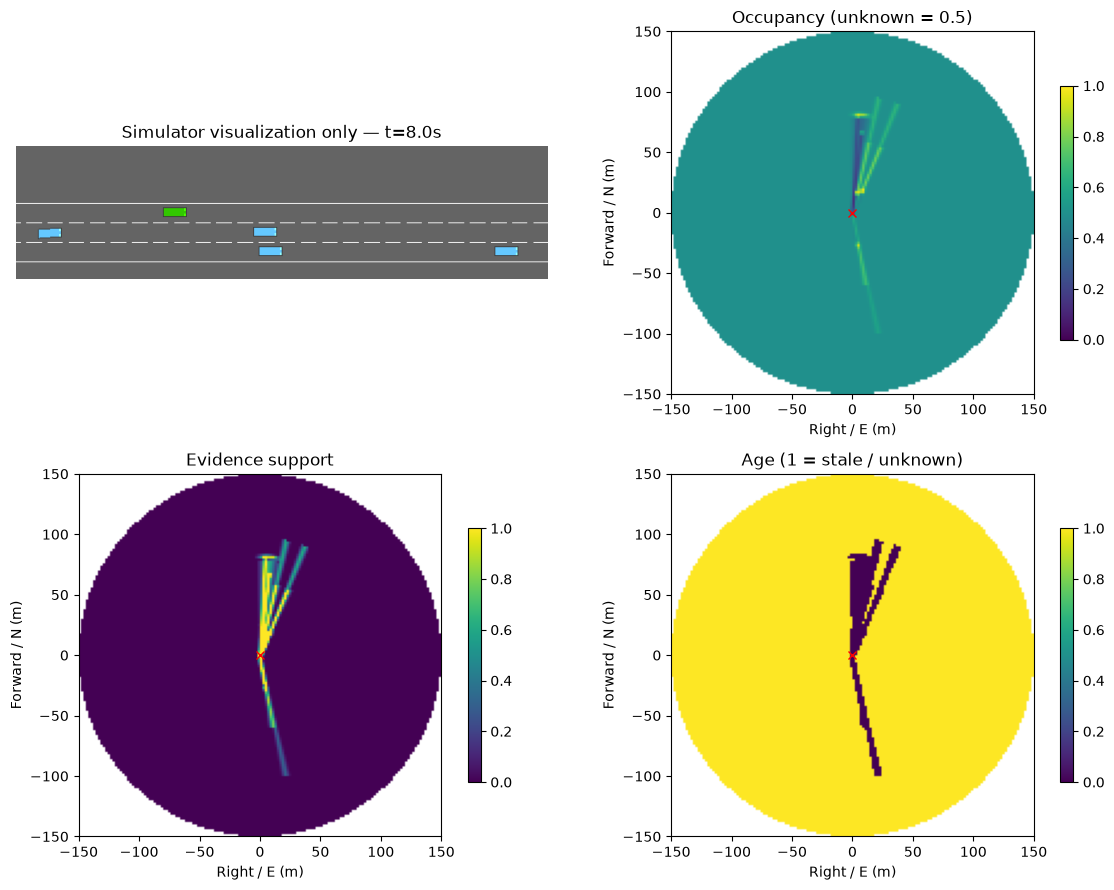

In [3]:
rollout = run_rollout(config, seed=SEED, mode=SENSING, capture=True)
display(pd.Series(summarize(rollout), name="Single run"))
display(rollout.history.head())
fig = plot_snapshot(rollout)
plt.show()

## 4. Inspect any captured decision

Change `SNAPSHOT_INDEX`: zero is reset, one is after the first decision, and -1 is
the final decision. Sensor status columns describe activation, readiness, whether
a recent packet exists (even an empty packet), and its normalized age.

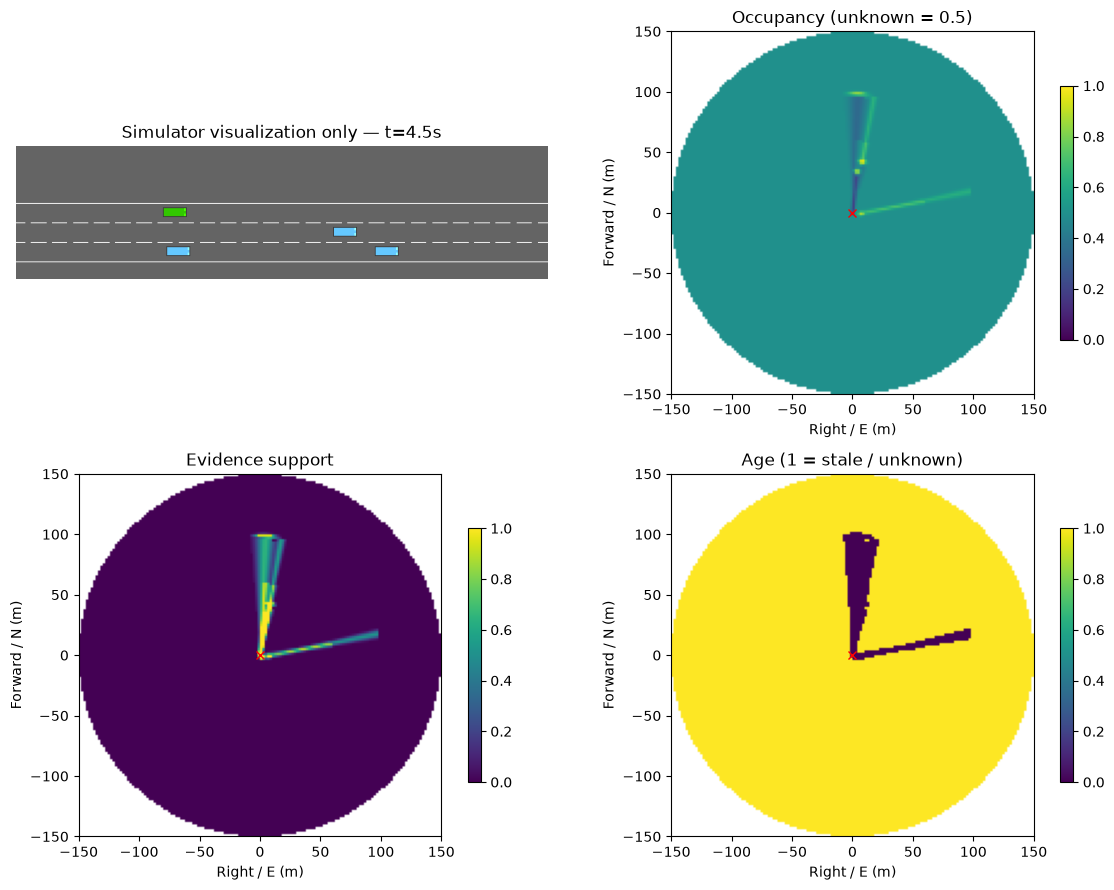

,requested_on,ready,recent_packet,normalized_age
rgb_N,1.0,1.0,1.0,0.033333
rgb_NE,1.0,1.0,1.0,0.033333
rgb_E,1.0,1.0,1.0,0.033333
rgb_SE,1.0,1.0,1.0,0.033333
rgb_S,1.0,1.0,1.0,0.033333
rgb_SW,1.0,1.0,1.0,0.033333
rgb_W,1.0,1.0,1.0,0.033333
rgb_NW,1.0,1.0,1.0,0.033333
event_N,1.0,1.0,1.0,0.006667
event_NE,1.0,1.0,1.0,0.006667


In [9]:
SNAPSHOT_INDEX = 9
fig = plot_snapshot(rollout, SNAPSHOT_INDEX)
plt.show()
display(pd.DataFrame(rollout.snapshots[SNAPSHOT_INDEX]["sensors"],
                     index=rollout.sensor_names,
                     columns=["requested_on", "ready", "recent_packet", "normalized_age"]))

## 5. Watch the drive and observation together

The animation shows the simulator beside the occupancy map at the same decision.
Playback speed does not change simulated sensor latency. Frames are captured only
for this short rollout, not for the later comparison sweep.

In [10]:
radius = rollout.radius_m
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
road_image = axes[0].imshow(rollout.frames[0])
axes[0].axis("off")
map_image = axes[1].imshow(np.ma.masked_where(
    rollout.snapshots[0]["valid_cells"] == 0, rollout.snapshots[0]["grid"][0]),
    extent=(-radius, radius, -radius, radius), vmin=0, vmax=1)
axes[1].plot(0, 0, "rx")
axes[1].set(xlabel="Right / E (m)", ylabel="Forward / N (m)")
fig.colorbar(map_image, ax=axes[1], shrink=.8)

def update_frame(i):
    road_image.set_data(rollout.frames[i])
    obs = rollout.snapshots[i]
    map_image.set_data(np.ma.masked_where(obs["valid_cells"] == 0, obs["grid"][0]))
    time_s = 0 if i == 0 else rollout.history.iloc[i - 1].time_s
    axes[0].set_title(f"Simulator visualization — t={time_s:.1f}s")
    axes[1].set_title("Agent occupancy evidence")
    return road_image, map_image

animation = FuncAnimation(fig, update_frame, frames=len(rollout.frames),
                          interval=1000 / config.highway["policy_frequency"], blit=False)
plt.close(fig)
display(HTML(animation.to_jshtml()))

## 6. Understand the reward and energy over time

Total reward combines driving reward with energy and uncertainty penalties.
The uncertainty statistic is occupancy entropy in a local driving corridor.
An empty detection packet does not establish that the road is clear.

Ask: does adding sensors reduce uncertainty enough to justify its modeled energy?
That tradeoff depends on the chosen reward weights; it is not a physical law.

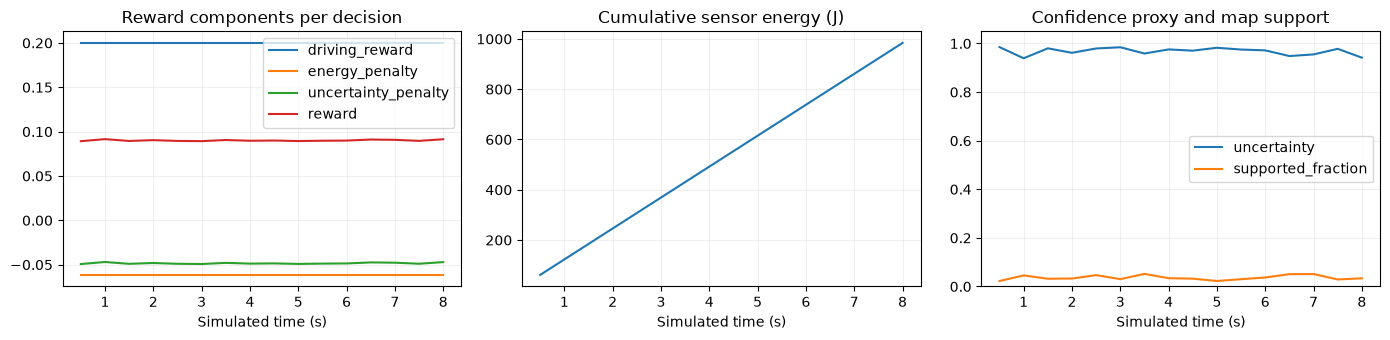

In [11]:
h = rollout.history
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
h.plot(x="time_s", y=["driving_reward", "energy_penalty", "uncertainty_penalty", "reward"], ax=axes[0])
h.plot(x="time_s", y="total_energy_j", ax=axes[1], legend=False)
h.plot(x="time_s", y=["uncertainty", "supported_fraction"], ax=axes[2])
axes[0].set_title("Reward components per decision")
axes[1].set_title("Cumulative sensor energy (J)")
axes[2].set(title="Confidence proxy and map support", ylim=(0, 1.05))
for ax in axes:
    ax.set_xlabel("Simulated time (s)")
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

## 7. Compare sensor combinations under different weather

This small sweep uses the **same traffic seeds and fixed driving actions** for
every sensor combination and condition. Weather currently changes perception,
not road friction or traffic behavior. Crash outcomes should therefore match for
the same seed. These are inspection baselines, not learned-policy evaluations.

The default runs 30 short episodes. Reduce the seed list or weather list for a
quicker check. Means over two seeds are exploratory; uncertainty is the model's
confidence proxy, not ground-truth error. Adding a sensor is not guaranteed to
improve a particular noisy run.

In [12]:
COMPARISON_SEEDS = [42, 43]
COMPARISON_WEATHER = ["clear", "fog", "glare"]
COMPARISON_MODES = ["off", "radar", "rgb", "radar_rgb", "all_on"]

records = []
for weather in COMPARISON_WEATHER:
    for mode in COMPARISON_MODES:
        for seed in COMPARISON_SEEDS:
            trial_config = copy.deepcopy(config)
            trial_config.weather.preset = weather
            trial = run_rollout(trial_config, seed=seed, mode=mode)
            records.append({"weather": weather, "sensing": mode, "seed": seed, **summarize(trial)})
    print(f"Finished {weather}")

comparison = pd.DataFrame(records)
summary = comparison.groupby(["weather", "sensing"], sort=False).agg(
    episodes=("seed", "count"), mean_energy_j=("energy_j", "mean"),
    mean_power_w=("mean_power_w", "mean"), mean_uncertainty=("mean_uncertainty", "mean"),
    mean_support=("mean_supported_fraction", "mean"), mean_return=("return", "mean"),
    crash_fraction=("crashed", "mean"))
display(summary.round(4))
# Confirm the comparison did not accidentally change driving with sensor mode.
assert comparison.groupby("seed").driving_return.nunique().eq(1).all()
assert comparison.groupby("seed").crashed.nunique().eq(1).all()

Finished clear
Finished fog
Finished glare


episodes  mean_energy_j  mean_power_w  mean_uncertainty  \
weather sensing                                                              
clear   off               2           10.8           1.8            1.0000   
        radar             2           70.2          11.7            0.9834   
        rgb               2          390.0          65.0            0.9812   
        radar_rgb         2          449.4          74.9            0.9808   
        all_on            2          738.0         123.0            0.9620   
fog     off               2           10.8           1.8            1.0000   
        radar             2           70.2          11.7            0.9836   
        rgb               2          390.0          65.0            0.9955   
        radar_rgb         2          449.4          74.9            0.9783   
        all_on            2          738.0         123.0            0.9774   
glare   off               2           10.8           1.8            1.0000   
        radar             2           70.2          11.7            0.9834   
        rgb               2          390.0          65.0            0.9943   
        radar_rgb         2          449.4          74.9            0.9763   
        all_on            2          738.0         123.0            0.9605   

                   mean_support  mean_return  crash_fraction  
weather sensing                                               
clear   off              0.0000      -0.7808             0.5  
        radar            0.0096      -0.8289             0.5  
        rgb              0.0168      -1.1499             0.5  
        radar_rgb        0.0236      -1.2077             0.5  
        all_on           0.0265      -1.4863             0.5  
fog     off              0.0000      -0.7808             0.5  
        radar            0.0120      -0.8284             0.5  
        rgb              0.0056      -1.1576             0.5  
        radar_rgb        0.0165      -1.2050             0.5  
        all_on           0.0168      -1.4937             0.5  
glare   off              0.0000      -0.7808             0.5  
        radar            0.0096      -0.8289             0.5  
        rgb              0.0110      -1.1568             0.5  
        radar_rgb        0.0196      -1.2039             0.5  
        all_on           0.0245      -1.4828             0.5

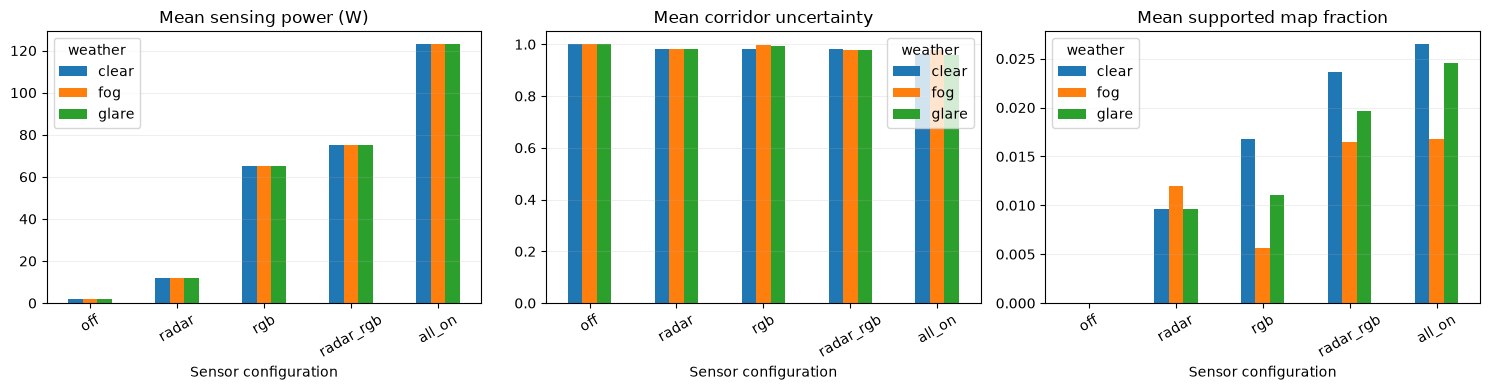

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes, ["mean_power_w", "mean_uncertainty", "mean_support"],
                           ["Mean sensing power (W)", "Mean corridor uncertainty", "Mean supported map fraction"]):
    values = summary[metric].unstack("weather").reindex(COMPARISON_MODES)
    values.plot.bar(ax=ax, rot=30, title=title)
    ax.set_xlabel("Sensor configuration")
    ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

## 8. Switch sensors off and watch information age

For this experiment, run all sensors for two seconds, then turn them off. Existing
measurements can remain visible for a while, but evidence decays and expires.
Standby power remains nonzero. If the episode crashes early, the plot may end
before the scheduled switch or expiration.

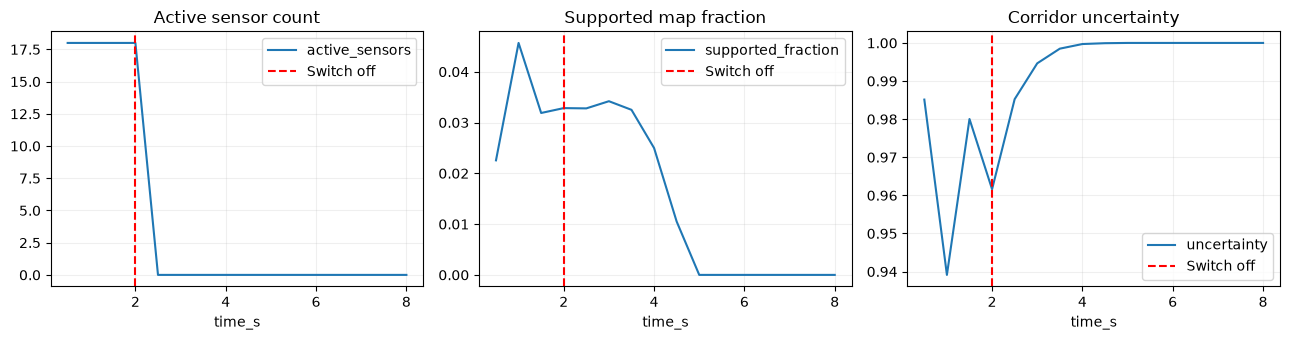

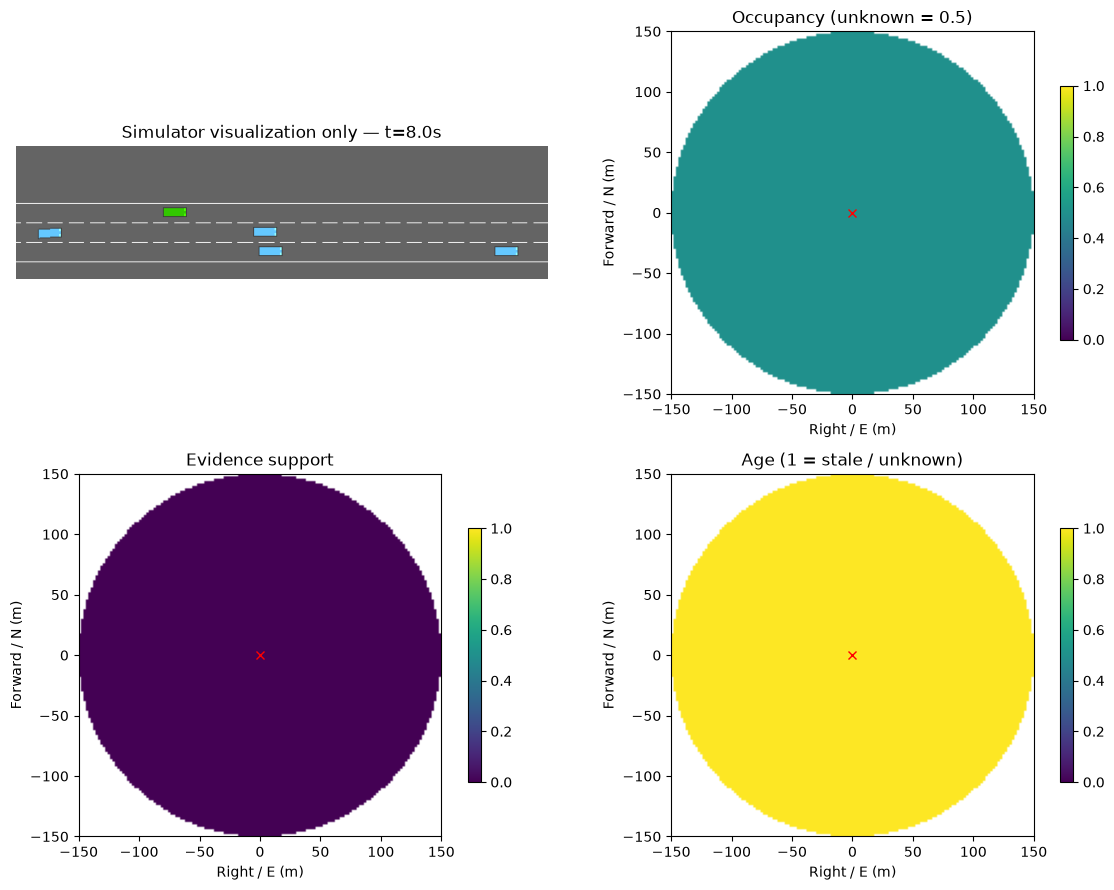

In [13]:
SWITCH_OFF_AT_S = 2.0

def on_then_off(time_s, trial_config):
    mode = "all_on" if time_s < SWITCH_OFF_AT_S else "off"
    return sensor_mask(trial_config, mode)

switch_config = copy.deepcopy(config)
switch_config.highway["duration"] = max(DURATION_S, 8)
switch_run = run_rollout(switch_config, seed=SEED, capture=True, schedule=on_then_off)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column, title in zip(axes, ["active_sensors", "supported_fraction", "uncertainty"],
                           ["Active sensor count", "Supported map fraction", "Corridor uncertainty"]):
    switch_run.history.plot(x="time_s", y=column, ax=ax, legend=False)
    ax.axvline(SWITCH_OFF_AT_S, color="red", linestyle="--", label="Switch off")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
fig = plot_snapshot(switch_run)
plt.show()

## 9. Your next controlled experiment

Change **one** assumption, rerun, and make a prediction first:

- Increase radar bearing noise. Does radar+RGB produce a more useful spatial map?
- Change glare direction to 180 degrees. Which camera views should degrade?
- Increase one sensor's latency to 0.5 s. Compare map age and first delivery.
- Set the uncertainty reward weight to zero. Does perception change, or only reward?
- Compare a 2 m and a 4 m grid. Does the coarser grid hide uncertainty or reduce work?

An example below compares delayed LiDAR against the same original scenario.
The shared sensor RNG means changing timing can also change later random draws;
repeat over multiple seeds before attributing every difference to latency.

In [14]:
delayed_config = copy.deepcopy(config)
for sensor in delayed_config.sensors:
    if sensor.kind == "lidar":
        sensor.latency_s = 0.5

delayed_run = run_rollout(delayed_config, seed=SEED, mode=SENSING)
display(pd.DataFrame([summarize(rollout), summarize(delayed_run)],
                     index=["Original", "LiDAR latency = 0.5 s"]).round(4))

,return,driving_return,energy_j,mean_power_w,mean_uncertainty,mean_supported_fraction,elapsed_s,crashed,completed
Original,1.4417,3.2,984.0,123.0,0.9679,0.0364,8.0,False,True
LiDAR latency = 0.5 s,1.4374,3.2,984.0,123.0,0.9733,0.0381,8.0,False,True


## 10. Save an experiment (optional)

Set `SAVE_RESULTS=True` to retain the configuration, scenario settings, tables,
and a preview. Each save creates a new directory. These outputs are ignored by
Git; the notebook and environment source remain the reproducible starting point.

In [15]:
SAVE_RESULTS = False
if SAVE_RESULTS:
    from datetime import datetime
    from zoneinfo import ZoneInfo
    import json
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S_%f")
    output = PROJECT_ROOT / "runs" / "environment" / stamp
    output.mkdir(parents=True, exist_ok=False)
    config.save(output / "config.json")
    (output / "run_settings.json").write_text(json.dumps({
        "seed": SEED, "sensing": SENSING, "comparison_seeds": COMPARISON_SEEDS,
        "comparison_weather": COMPARISON_WEATHER, "comparison_modes": COMPARISON_MODES,
        "switch_off_at_s": SWITCH_OFF_AT_S,
        "python": sys.version, "package_versions": {
            name: version(name) for name in ["highway-env", "gymnasium", "numpy", "pandas", "matplotlib"]},
    }, indent=2))
    rollout.history.to_csv(output / "single_run.csv", index=False)
    comparison.to_csv(output / "comparison.csv", index=False)
    summary.to_csv(output / "summary.csv")
    switch_run.history.to_csv(output / "switching.csv", index=False)
    delayed_config.save(output / "delayed_lidar_config.json")
    delayed_run.history.to_csv(output / "delayed_lidar.csv", index=False)
    fig = plot_snapshot(rollout)
    fig.savefig(output / "preview.png", dpi=130)
    plt.close(fig)
    print("Saved:", output)
else:
    print("Saving is off. Set SAVE_RESULTS=True to keep a run.")

Saving is off. Set SAVE_RESULTS=True to keep a run.


What this notebook establishes: the sensing pipeline runs, measurements arrive
with delay, masks change available information, weather changes modeled sensing,
and energy is accounted for. It does not establish real sensor accuracy or a
safety benefit. The next learning experiment can use these fixed sensing modes as
baselines for an agent that chooses sensing and driving from observations.